In [1]:
import hashlib
import importlib
import json
import platform
import shutil
import subprocess
import sys
import time
from importlib.metadata import version
from pathlib import Path

NOTEBOOK = "05_liquidity_regimes.ipynb"
notebook_started = time.perf_counter()

candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
REPO_ROOT = next(
    (
        path for path in candidates
        if (path / "pyproject.toml").is_file()
        and (path / "configs/research_config.example.json").is_file()
        and (path / "src/eurusd_research/features.py").is_file()
    ),
    None,
)

if REPO_ROOT is None:
    entered = input(
        "Full repository path containing pyproject.toml, configs, and src: "
    ).strip().strip('"')
    if not entered:
        raise ValueError("Enter the full repository folder path.")
    REPO_ROOT = Path(entered).expanduser().resolve()

for relative in (
    "pyproject.toml",
    "configs/research_config.example.json",
    "src/eurusd_research/features.py",
    "src/eurusd_research/evaluation.py",
):
    if not (REPO_ROOT / relative).is_file():
        raise RuntimeError(f"Required project file missing: {relative}")

import numpy as np
import pandas as pd

from eurusd_research.config import load_config
from eurusd_research import features as feature_io
from eurusd_research.data import _sha256
from eurusd_research.evaluation import regression_metrics
from eurusd_research.validation import utc, validate_plan

config = load_config(REPO_ROOT)
feature_settings = config["sampling_features"]
plan = validate_plan(config["pilot_validation_plan"])

baseline_manifest_path = (
    REPO_ROOT / config["active_baseline_manifest"]
).resolve()
baseline_run = json.loads(
    baseline_manifest_path.read_text(encoding="utf-8")
)
if baseline_run["status"] != "complete":
    raise RuntimeError("Notebook 04 must have a completed baseline run.")
if baseline_run["validation"]["pilot_holdout_evaluated"]:
    raise RuntimeError("Expected an untouched pilot holdout.")

baseline_id = baseline_run["run_id"]
HORIZONS = baseline_run["completed_horizons"]
if HORIZONS != [1, 5, 30, 60]:
    raise RuntimeError("Expected completed horizons [1, 5, 30, 60].")

feature_manifest_path = (
    REPO_ROOT / config["active_features_manifest"]
).resolve()
label_manifest_path = (
    REPO_ROOT / config["active_labels_manifest"]
).resolve()

feature_state = json.loads(
    feature_manifest_path.read_text(encoding="utf-8")
)
if feature_state["status"] != "complete":
    raise RuntimeError("The selected feature generation is incomplete.")
if feature_state["identity"]["settings"] != feature_settings:
    raise RuntimeError("Current feature settings differ from the saved generation.")
if feature_state["job_id"] != baseline_run["identity"]["feature_job_id"]:
    raise RuntimeError("The active features differ from the baseline inputs.")

input_hashes = {
    "features": _sha256(feature_manifest_path),
    "labels": _sha256(label_manifest_path),
}
if input_hashes != baseline_run["identity"]["input_manifest_sha256"]:
    raise RuntimeError("The baseline input manifests have changed.")
if (
    _sha256(REPO_ROOT / "src/eurusd_research/evaluation.py")
    != baseline_run["identity"]["implementation_sha256"]["evaluation"]
):
    raise RuntimeError("The evaluation implementation differs from Notebook 04.")

windows = baseline_run["identity"]["windows"]
periods = {item["role"]: item for item in plan["periods"]}
for role in ("train", "validation"):
    if not (
        utc(periods[role]["start_utc"])
        <= utc(windows[role]["start_utc"])
        < utc(windows[role]["end_utc"])
        <= utc(periods[role]["end_utc"])
    ):
        raise RuntimeError(f"The saved {role} window is incompatible with the plan.")

regime_settings = config.get("liquidity_regimes", {
    "lookback_seconds": 60,
    "high_quantile": 0.95,
    "low_quantile": 0.10,
    "minimum_training_rows": 1000,
    "block_hours": 6,
    "max_rows_per_scope": 300500,
    "max_frame_mib": 128,
    "max_combined_frame_mib": 192,
    "small_group_row_threshold": 1000,
})

W = regime_settings["lookback_seconds"]
if (
    W not in feature_settings["volatility_windows_seconds"]
    or W not in feature_settings["activity_windows_seconds"]
):
    raise RuntimeError("The requested regime window lacks saved source features.")

versions = {
    name: version(name)
    for name in ("numpy", "pandas", "pyarrow", "duckdb", "pytest", "matplotlib")
}
new_sources = {}

print("NOTEBOOK_05_PREFLIGHT")
print("Repository:", REPO_ROOT)
print("Baseline run:", baseline_id)
print("Feature generation:", feature_state["job_id"])
print("Windows:", json.dumps(windows, indent=2))
print("Regime lookback:", W, "seconds")
print("Data locations will be resolved relative to this repository.")
print("No installation or kernel restart is needed.")

NOTEBOOK_05_PREFLIGHT
Repository: C:\Users\Ijzd4\Desktop\EURUSD Fair-Value and Liquidity
Baseline run: 954fa0296d02480ea2d473c0
Feature generation: fb7eb0c3f6e51a16fe2e8ee5
Windows: {
  "train": {
    "end_utc": "2016-01-20T00:00:00+00:00",
    "selected_active_dates": [
      "2016-01-17",
      "2016-01-18",
      "2016-01-19"
    ],
    "start_utc": "2016-01-17T00:00:00+00:00"
  },
  "validation": {
    "end_utc": "2016-01-22T00:00:00+00:00",
    "selected_active_dates": [
      "2016-01-20",
      "2016-01-21"
    ],
    "start_utc": "2016-01-20T00:00:00+00:00"
  }
}
Regime lookback: 60 seconds
Data locations will be resolved relative to this repository.
No installation or kernel restart is needed.


In [2]:
new_sources["src/eurusd_research/regimes.py"] = r'''
"""Causal liquidity metrics and training-only transparent regime rules."""

from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from . import features as io
from .data import _sha256
from .validation import utc


REGIME_NAMES = ["unavailable", "unclassified", "stressed", "thin", "normal"]
METRIC_COLUMNS = [
    "metric_spread_mean_pips",
    "metric_volatility_pips",
    "metric_min_side_size_mean",
    "metric_quote_count",
]


def input_columns(window):
    return [
        "feature_timestamp_utc", "source_timestamp_utc",
        "price_valid", "size_pair_valid",
        "snapshot_staleness_seconds",
        "spread_pips", "bid_size", "ask_size",
        "price_path_break", "unusable_size_observed_1s",
        f"realized_vol_{window}s_pips",
        f"snapshot_count_{window}s",
    ]


def build_liquidity_metrics(frame, start, end, settings):
    start, end = utc(start), utc(end)
    window = settings["lookback_seconds"]
    if type(window) is not int or window < 1 or start >= end:
        raise ValueError("Invalid liquidity window or output range.")

    q = frame[input_columns(window)].copy().reset_index(drop=True)
    for name in ("feature_timestamp_utc", "source_timestamp_utc"):
        if not isinstance(q[name].dtype, pd.DatetimeTZDtype):
            raise ValueError("Input timestamps must explicitly carry a timezone.")
        q[name] = q[name].dt.tz_convert("UTC").astype("datetime64[us, UTC]")

    times = q["feature_timestamp_utc"]
    if (
        len(q) == 0 or times.isna().any() or not times.is_unique
        or not times.is_monotonic_increasing
        or not times.diff().iloc[1:].eq(pd.Timedelta(seconds=1)).all()
    ):
        raise ValueError("Liquidity inputs require a complete one-second grid.")
    if (q["source_timestamp_utc"] > times).any():
        raise ValueError("A future source entered liquidity inputs.")

    for name in (
        "price_valid", "size_pair_valid",
        "price_path_break", "unusable_size_observed_1s",
    ):
        if q[name].isna().any() or not pd.api.types.is_bool_dtype(q[name]):
            raise ValueError(f"{name} must contain nonmissing booleans.")

    continuous = (
        q["price_valid"].rolling(window + 1, min_periods=window + 1)
        .sum().eq(window + 1)
        & q["price_path_break"].rolling(window, min_periods=window)
        .sum().eq(0)
    )
    size_complete = (
        continuous
        & q["size_pair_valid"].rolling(window, min_periods=window)
        .sum().eq(window)
        & q["unusable_size_observed_1s"].rolling(window, min_periods=window)
        .sum().eq(0)
    )

    result = q[[
        "feature_timestamp_utc", "source_timestamp_utc",
        "price_valid", "size_pair_valid",
        "snapshot_staleness_seconds", "spread_pips", "bid_size", "ask_size",
    ]].copy()
    result["metric_lookback_seconds"] = window
    result["metric_spread_mean_pips"] = (
        q["spread_pips"].where(q["price_valid"])
        .rolling(window, min_periods=window).mean().where(continuous)
    )
    result["metric_volatility_pips"] = (
        q[f"realized_vol_{window}s_pips"].where(continuous)
    )
    minimum_size = pd.Series(
        np.minimum(q["bid_size"], q["ask_size"]), index=q.index
    ).where(q["size_pair_valid"])
    result["metric_min_side_size_mean"] = (
        minimum_size.rolling(window, min_periods=window)
        .mean().where(size_complete)
    )
    result["metric_quote_count"] = (
        q[f"snapshot_count_{window}s"].where(continuous)
    )

    values = result[METRIC_COLUMNS].to_numpy(dtype=float)
    result["regime_metrics_complete"] = (
        q["price_valid"]
        & np.isfinite(values).all(axis=1)
        & (values >= 0).all(axis=1)
    )

    result = result.loc[
        result["feature_timestamp_utc"].ge(start)
        & result["feature_timestamp_utc"].lt(end)
    ].reset_index(drop=True)
    if len(result) != int((end - start).total_seconds()):
        raise ValueError("Liquidity output row conservation failed.")
    return result


def fit_regime_thresholds(metrics, settings, start, end):
    start, end = utc(start), utc(end)
    low, high = settings["low_quantile"], settings["high_quantile"]
    if not 0 < low < high < 1:
        raise ValueError("Quantiles must satisfy 0 < low < high < 1.")

    selected = metrics.loc[
        metrics["feature_timestamp_utc"].ge(start)
        & metrics["feature_timestamp_utc"].lt(end)
        & metrics["regime_metrics_complete"]
    ]
    if len(selected) < settings["minimum_training_rows"]:
        raise ValueError("Too few complete training rows for regime thresholds.")
    if not selected["metric_lookback_seconds"].eq(
        settings["lookback_seconds"]
    ).all():
        raise ValueError("Metric and threshold lookback windows differ.")

    values = selected[METRIC_COLUMNS].to_numpy(dtype=float)
    if not np.isfinite(values).all() or (values < 0).any():
        raise ValueError("Complete training metrics must be finite and nonnegative.")

    return {
        "rule_version": "trailing_quantiles_v1",
        "settings": dict(settings),
        "fit_start_utc": start.isoformat(),
        "fit_end_utc_exclusive": end.isoformat(),
        "training_metric_rows": len(selected),
        "cutoffs": {
            "spread_high_pips": float(
                selected["metric_spread_mean_pips"].quantile(high)
            ),
            "volatility_high_pips": float(
                selected["metric_volatility_pips"].quantile(high)
            ),
            "depth_low_source_units": float(
                selected["metric_min_side_size_mean"].quantile(low)
            ),
            "activity_low_snapshots": float(
                selected["metric_quote_count"].quantile(low)
            ),
        },
    }


def classify_regimes(metrics, thresholds):
    result = metrics.copy()
    if not result["metric_lookback_seconds"].eq(
        thresholds["settings"]["lookback_seconds"]
    ).all():
        raise ValueError("Metric and fitted threshold windows differ.")

    cut = thresholds["cutoffs"]
    result["high_spread"] = result["metric_spread_mean_pips"].gt(
        cut["spread_high_pips"]
    )
    result["high_volatility"] = result["metric_volatility_pips"].gt(
        cut["volatility_high_pips"]
    )
    result["low_depth"] = result["metric_min_side_size_mean"].lt(
        cut["depth_low_source_units"]
    )
    result["low_activity"] = result["metric_quote_count"].lt(
        cut["activity_low_snapshots"]
    )
    result["zero_side_size"] = (
        result["bid_size"].eq(0) | result["ask_size"].eq(0)
    )

    result["liquidity_regime"] = pd.Series(np.select(
        [
            ~result["price_valid"].to_numpy(),
            ~result["regime_metrics_complete"].to_numpy(),
            (result["high_spread"] | result["high_volatility"]).to_numpy(),
            (
                result["low_depth"] | result["low_activity"]
                | result["zero_side_size"]
            ).to_numpy(),
        ],
        ["unavailable", "unclassified", "stressed", "thin"],
        default="normal",
    ), index=result.index, dtype="string")
    return result
'''.lstrip()

print("Prepared liquidity metrics and regime rules.")

Prepared liquidity metrics and regime rules.


In [3]:
new_sources["src/eurusd_research/regimes.py"] += r'''


def load_regime_inputs(state, repository_root, start, end,
                       settings, feature_settings):
    start, end = utc(start), utc(end)
    if state["status"] != "complete":
        raise ValueError("A completed feature generation is required.")

    available_start = utc(state["identity"]["start_utc"])
    available_end = utc(state["identity"]["end_utc"])
    if not available_start <= start < end <= available_end:
        raise ValueError("Requested scope exceeds feature coverage.")

    read_start = max(
        available_start,
        start - pd.Timedelta(seconds=settings["lookback_seconds"]),
    )
    expected = int((end - read_start).total_seconds())
    if expected > settings["max_rows_per_scope"]:
        raise ValueError("Liquidity input scope exceeds its row guard.")

    output = (
        Path(repository_root) / "data/processed/features" / state["job_id"]
    ).resolve()
    files = []
    for part in state["parts"]:
        if utc(part["start_utc"]) >= end or utc(part["end_utc"]) <= read_start:
            continue
        path = (output / part["path"]).resolve()
        if not path.is_relative_to(output):
            raise RuntimeError("A feature part escapes its generation directory.")
        if not path.is_file() or _sha256(path) != part["sha256"]:
            raise RuntimeError(f"Feature integrity failed: {path}")
        parquet = pq.ParquetFile(path)
        if (
            parquet.metadata.num_rows != part["rows"]
            or io._schema_hash(parquet.schema_arrow) != part["schema_sha256"]
        ):
            raise RuntimeError("Feature part schema or row count changed.")
        files.append(str(path))

    if not files:
        raise ValueError("No feature parts intersect the requested scope.")

    columns = input_columns(settings["lookback_seconds"])
    working = (
        Path(repository_root) / "artifacts/manifests/regimes/loading"
        / start.strftime("%Y%m%dT%H%M%S")
    )
    connection = io._connect(files, "features", working, feature_settings)
    try:
        frame = connection.execute(f"""
            SELECT {", ".join(columns)} FROM features
            WHERE feature_timestamp_utc >= CAST(? AS TIMESTAMPTZ)
              AND feature_timestamp_utc < CAST(? AS TIMESTAMPTZ)
            ORDER BY feature_timestamp_utc LIMIT ?
        """, [
            read_start.isoformat(), end.isoformat(),
            settings["max_rows_per_scope"] + 1,
        ]).fetchdf()
    finally:
        connection.close()

    frame = io.normalise_feature_types(frame)
    if len(frame) != expected:
        raise RuntimeError("Liquidity input row conservation failed.")
    observed_bytes = int(frame.memory_usage(index=True, deep=True).sum())
    if observed_bytes > settings["max_frame_mib"] * 1024**2:
        raise RuntimeError("Liquidity input exceeds its dataframe memory guard.")

    return frame, {
        "input_rows_including_context": len(frame),
        "selected_files_verified": len(files),
        "observed_input_frame_bytes": observed_bytes,
        "read_start_utc": read_start.isoformat(),
    }
'''

print("Prepared bounded, location-aware feature loading.")

Prepared bounded, location-aware feature loading.


In [4]:
new_sources["tests/test_regimes.py"] = r'''
import numpy as np
import pandas as pd
import pytest

from eurusd_research import features as io
from eurusd_research.regimes import (
    build_liquidity_metrics, classify_regimes,
    fit_regime_thresholds, load_regime_inputs,
)


def settings():
    return {
        "lookback_seconds": 60,
        "high_quantile": 0.95,
        "low_quantile": 0.10,
        "minimum_training_rows": 3,
        "max_rows_per_scope": 1000,
        "max_frame_mib": 20,
    }


def inputs(n=240):
    times = pd.date_range(
        "2020-01-31T23:58:00Z", periods=n, freq="s"
    )
    return pd.DataFrame({
        "feature_timestamp_utc": times,
        "source_timestamp_utc": times,
        "price_valid": np.ones(n, dtype=bool),
        "size_pair_valid": np.ones(n, dtype=bool),
        "snapshot_staleness_seconds": np.zeros(n),
        "spread_pips": np.arange(n, dtype=float),
        "bid_size": np.full(n, 2.0),
        "ask_size": np.full(n, 3.0),
        "price_path_break": np.r_[True, np.zeros(n - 1, dtype=bool)],
        "unusable_size_observed_1s": np.zeros(n, dtype=bool),
        "realized_vol_60s_pips": np.ones(n),
        "snapshot_count_60s": np.full(n, 60.0),
    })


def metric_rows(n=20):
    times = pd.date_range("2020-01-01", periods=n, freq="s", tz="UTC")
    return pd.DataFrame({
        "feature_timestamp_utc": times,
        "price_valid": np.ones(n, dtype=bool),
        "regime_metrics_complete": np.ones(n, dtype=bool),
        "metric_lookback_seconds": np.full(n, 60),
        "metric_spread_mean_pips": np.arange(1, n + 1, dtype=float),
        "metric_volatility_pips": np.arange(1, n + 1, dtype=float),
        "metric_min_side_size_mean": np.arange(1, n + 1, dtype=float),
        "metric_quote_count": np.arange(1, n + 1, dtype=float),
        "bid_size": np.ones(n),
        "ask_size": np.ones(n),
    })


def test_thresholds_ignore_rows_outside_training():
    q = metric_rows()
    start = q["feature_timestamp_utc"].iloc[0]
    end = q["feature_timestamp_utc"].iloc[10]
    original = fit_regime_thresholds(q, settings(), start, end)

    changed = q.copy()
    changed.loc[10:, [
        "metric_spread_mean_pips", "metric_volatility_pips",
        "metric_min_side_size_mean", "metric_quote_count",
    ]] = 1000000.0
    assert original == fit_regime_thresholds(changed, settings(), start, end)
    assert original["training_metric_rows"] == 10


def test_precedence_missingness_zero_size_and_strict_ties():
    q = metric_rows(6)
    for name in (
        "metric_spread_mean_pips", "metric_volatility_pips",
        "metric_min_side_size_mean", "metric_quote_count",
    ):
        q[name] = 1.0
    threshold = {
        "settings": settings(),
        "cutoffs": {
            "spread_high_pips": 1.0, "volatility_high_pips": 1.0,
            "depth_low_source_units": 1.0, "activity_low_snapshots": 1.0,
        },
    }
    q.loc[0, "metric_spread_mean_pips"] = 2.0
    q.loc[0, "metric_min_side_size_mean"] = 0.5
    q.loc[1, "metric_min_side_size_mean"] = 0.5
    q.loc[2, "regime_metrics_complete"] = False
    q.loc[3, "price_valid"] = False
    q.loc[4, "bid_size"] = 0.0

    assert classify_regimes(q, threshold)["liquidity_regime"].tolist() == [
        "stressed", "thin", "unclassified", "unavailable", "thin", "normal"
    ]


def test_trailing_mean_is_hand_checkable():
    q = inputs()
    start = q["feature_timestamp_utc"].iloc[60]
    result = build_liquidity_metrics(
        q, start, start + pd.Timedelta(seconds=1), settings()
    )
    assert result.loc[0, "metric_spread_mean_pips"] == pytest.approx(30.5)
    assert result.loc[0, "metric_min_side_size_mean"] == 2.0
    assert result.loc[0, "regime_metrics_complete"]


def test_future_append_does_not_change_past_metrics():
    q = inputs()
    start = q["feature_timestamp_utc"].iloc[60]
    end = q["feature_timestamp_utc"].iloc[120]
    before = build_liquidity_metrics(q.iloc[:120], start, end, settings())
    after = build_liquidity_metrics(q, start, end, settings())
    pd.testing.assert_frame_equal(before, after)


def test_partition_consistency_across_midnight_and_breaks():
    q = inputs()
    q.loc[110, "price_valid"] = False
    q.loc[[110, 111], "price_path_break"] = True
    start = q["feature_timestamp_utc"].iloc[60]
    middle = q["feature_timestamp_utc"].iloc[120]
    end = q["feature_timestamp_utc"].iloc[180]

    whole = build_liquidity_metrics(q, start, end, settings())
    left = build_liquidity_metrics(q.iloc[:120], start, middle, settings())
    right = build_liquidity_metrics(q.iloc[60:180], middle, end, settings())
    pd.testing.assert_frame_equal(
        whole, pd.concat([left, right], ignore_index=True)
    )


def test_invalid_size_event_preserves_price_metrics():
    q = inputs()
    q.loc[70, "unusable_size_observed_1s"] = True
    start = q["feature_timestamp_utc"].iloc[80]
    result = build_liquidity_metrics(
        q, start, start + pd.Timedelta(seconds=1), settings()
    )
    assert np.isfinite(result.loc[0, "metric_spread_mean_pips"])
    assert np.isfinite(result.loc[0, "metric_volatility_pips"])
    assert pd.isna(result.loc[0, "metric_min_side_size_mean"])
    assert not result.loc[0, "regime_metrics_complete"]


def test_loader_resolves_moved_generation_and_skips_holdout(tmp_path):
    q = inputs(180)
    output = tmp_path / "data/processed/features/synthetic"
    record = io._save_frame(q, output / "part.parquet")
    first = q["feature_timestamp_utc"].iloc[0]
    last = q["feature_timestamp_utc"].iloc[-1] + pd.Timedelta(seconds=1)
    record.update({
        "path": "part.parquet",
        "start_utc": first.isoformat(), "end_utc": last.isoformat(),
    })
    state = {
        "status": "complete",
        "job_id": "synthetic",
        "output_dir": "an_old_location_that_must_not_be_used",
        "identity": {
            "start_utc": first.isoformat(), "end_utc": last.isoformat(),
        },
        "parts": [
            record,
            {
                "path": "holdout_must_not_be_opened.parquet",
                "start_utc": last.isoformat(),
                "end_utc": (last + pd.Timedelta(seconds=1)).isoformat(),
            },
        ],
    }
    start = first + pd.Timedelta(seconds=60)
    end = first + pd.Timedelta(seconds=120)
    loaded, diagnostic = load_regime_inputs(
        state, tmp_path, start, end, settings(),
        {"duckdb_memory_limit": "128MB", "duckdb_temp_limit": "1GB"},
    )
    assert len(loaded) == 120
    assert diagnostic["selected_files_verified"] == 1
'''.lstrip()

print("Prepared test_regimes.py")

Prepared test_regimes.py


In [5]:
for relative, source in new_sources.items():
    path = REPO_ROOT / relative
    if path.exists():
        existing = path.read_text(encoding="utf-8").replace("\r\n", "\n")
        if existing != source:
            raise RuntimeError(
                f"Existing contents differ: {relative}. Stop before overwriting."
            )

for relative, source in new_sources.items():
    path = REPO_ROOT / relative
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        with path.open("x", encoding="utf-8", newline="\n") as handle:
            handle.write(source)
        print("CREATED", relative)
    else:
        print("REUSED", relative)

importlib.invalidate_caches()

probe = subprocess.run(
    [
        sys.executable, "-c",
        "from pathlib import Path; from eurusd_research import regimes; "
        "print(Path(regimes.__file__).resolve())",
    ],
    cwd=REPO_ROOT / "notebooks",
    capture_output=True,
    text=True,
)
if probe.returncode:
    print(probe.stdout)
    print(probe.stderr)
    raise RuntimeError("Regime imports failed.")

expected_module = REPO_ROOT / "src/eurusd_research/regimes.py"
if Path(probe.stdout.strip()).resolve() != expected_module.resolve():
    raise RuntimeError("Imported a different regime module.")

test_run = subprocess.run(
    [sys.executable, "-m", "pytest", "tests", "-q", "--color=no"],
    cwd=REPO_ROOT,
    capture_output=True,
    text=True,
)
print(test_run.stdout)
if test_run.stderr:
    print(test_run.stderr)
if test_run.returncode:
    raise RuntimeError("Tests failed. Stop and return Cell 10 output.")

test_summary = test_run.stdout.strip().splitlines()[-1]

for relative in (
    "data/processed/regimes/example.parquet",
    "artifacts/manifests/regimes/example.json",
    "reports/private/notebook05_execution.json",
    "reports/tables/regimes/example.csv",
    "reports/figures/regimes/example.png",
):
    check = subprocess.run(
        ["git", "check-ignore", "--no-index", "-q", "--", relative],
        cwd=REPO_ROOT,
        capture_output=True,
        text=True,
    )
    if check.returncode != 0:
        raise RuntimeError(f"Generated output is not ignored: {relative}")

public_check = subprocess.run(
    [
        "git", "check-ignore", "--no-index", "-q", "--",
        "reports/research_hypotheses.md",
    ],
    cwd=REPO_ROOT,
    capture_output=True,
    text=True,
)
if public_check.returncode != 1:
    raise RuntimeError("The safe public hypothesis record is unexpectedly ignored.")

from eurusd_research.regimes import (
    METRIC_COLUMNS, REGIME_NAMES,
    build_liquidity_metrics, classify_regimes,
    fit_regime_thresholds, load_regime_inputs,
)

print("PASS: imports, tests, and output ignore rules.")

CREATED src/eurusd_research/regimes.py
CREATED tests/test_regimes.py
....................................................                     [100%]
52 passed in 6.63s

PASS: imports, tests, and output ignore rules.


In [6]:
def relative_path(path):
    return Path(path).resolve().relative_to(REPO_ROOT).as_posix()


def update_section(path, name, content):
    begin = f"<!-- {name}:BEGIN -->"
    finish = f"<!-- {name}:END -->"
    existing = path.read_text(encoding="utf-8") if path.exists() else ""
    if existing.count(begin) != existing.count(finish) or existing.count(begin) > 1:
        raise RuntimeError(f"Malformed generated section: {path.name}")
    block = f"{begin}\n{content.strip()}\n{finish}"
    if begin in existing:
        left, remainder = existing.split(begin, 1)
        _, right = remainder.split(finish, 1)
        result = left + block + right
    else:
        result = existing.rstrip() + "\n\n" + block + "\n"
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8", newline="\n") as handle:
        handle.write(result)


hypothesis_path = REPO_ROOT / "reports/research_hypotheses.md"

hypothesis_note = """
# H001 — Displayed size conditional on a preceding price move

Status: recorded for later development testing; not executed.

Origin: Raymond Fendi proposed that a price move accompanied by substantial
available size might carry information about continuation.

Timing: formulated after reviewing the Notebook 04 pilot results.
This is exploratory, not a hypothesis registered before that pilot.

## Research question

Does the side, relative magnitude, and persistence of displayed size improve
forecasts conditional on a preceding price move and liquidity conditions?

## Proposed first specification

- Preceding move: 30-second trailing mid-price change.
- Primary future horizon: 5 seconds.
- Nonzero preceding moves define a direction; zero moves are reported separately.
- Direction-aligned imbalance:
  sign(preceding move) multiplied by current size imbalance.
- Persistence candidate: direction-aligned mean imbalance over the preceding
  10 sampled seconds, including the current sample, with valid size coverage.
- Relative supporting-side size: bid size for an upward preceding move,
  ask size for a downward move, normalized using the corresponding
  training-only side-size median.

The continuation hypothesis is that the expected direction-signed future
price change increases with direction-aligned size support, conditional on
preceding move magnitude, spread, volatility, quote activity, and staleness.

Substantial opposing-side size may instead be associated with resistance
or absorption. These are hypotheses, not established mechanisms.

## Planned comparison safeguards

Before execution, freeze the exact implementation, development dates,
numerical zero tolerance, controls, and limited comparison budget.

Use identical training and evaluation observations for each ablation.
Fit normalization and any thresholds on training data only.

Evaluate incremental forecast errors and conditional continuation estimates.
Use time-block uncertainty and report stability across development periods.
Report freshness and carried-forward-snapshot sensitivity.

The already inspected January 20–21 pilot is not fresh confirmation for H001.
Do not use the reserved holdout to choose its specification.

## Observability limits

Displayed size is available quoted quantity, not executed trade volume.
Changes in quoted size do not identify executions, cancellations,
replenishment, participant identity, or intent.

Persistence means persistence observed in this feed.
Export size denomination remains unresolved.

## Execution and review

No H001-specific model or statistical test has been executed.
Notebook 05 regime diagnostics do not constitute this test.
Owner review of a future implemented test remains pending.
"""

update_section(hypothesis_path, "H001", hypothesis_note)

print("Recorded H001:", relative_path(hypothesis_path))
print("Status: pending future testing; no H001 model fitted.")

Recorded H001: reports/research_hypotheses.md
Status: pending future testing; no H001 model fitted.


In [7]:
if shutil.disk_usage(REPO_ROOT).free < 2 * 1024**3:
    raise RuntimeError("Free at least 2 GiB before saving regime outputs.")

metrics_started = time.perf_counter()
regime_frames = {}
input_diagnostics = {}

for role in ("train", "validation"):
    window = windows[role]
    inputs, diagnostic = load_regime_inputs(
        feature_state, REPO_ROOT,
        window["start_utc"], window["end_utc"],
        regime_settings, feature_settings,
    )
    regime_frames[role] = build_liquidity_metrics(
        inputs, window["start_utc"], window["end_utc"], regime_settings
    )
    input_diagnostics[role] = diagnostic
    del inputs

regime_frame_bytes = {
    role: int(frame.memory_usage(index=True, deep=True).sum())
    for role, frame in regime_frames.items()
}
if sum(regime_frame_bytes.values()) > (
    regime_settings["max_combined_frame_mib"] * 1024**2
):
    raise RuntimeError("Combined metric frames exceed their memory guard.")

metrics_runtime = time.perf_counter() - metrics_started

print("LIQUIDITY_METRIC_INPUTS")
print(json.dumps(input_diagnostics, indent=2))
for role, frame in regime_frames.items():
    print(role, {
        "clock_rows": len(frame),
        "price_valid_rows": int(frame["price_valid"].sum()),
        "complete_metric_rows": int(frame["regime_metrics_complete"].sum()),
    })

LIQUIDITY_METRIC_INPUTS
{
  "train": {
    "input_rows_including_context": 259260,
    "selected_files_verified": 13,
    "observed_input_frame_bytes": 17629812,
    "read_start_utc": "2016-01-16T23:59:00+00:00"
  },
  "validation": {
    "input_rows_including_context": 172860,
    "selected_files_verified": 9,
    "observed_input_frame_bytes": 11754612,
    "read_start_utc": "2016-01-19T23:59:00+00:00"
  }
}
train {'clock_rows': 259200, 'price_valid_rows': 178214, 'complete_metric_rows': 171361}
validation {'clock_rows': 172800, 'price_valid_rows': 172547, 'complete_metric_rows': 171133}


In [8]:
thresholds = fit_regime_thresholds(
    regime_frames["train"],
    regime_settings,
    windows["train"]["start_utc"],
    windows["train"]["end_utc"],
)

baseline_manifest_hash = _sha256(baseline_manifest_path)
identity = {
    "baseline_run_id": baseline_id,
    "baseline_manifest_sha256": baseline_manifest_hash,
    "feature_manifest_sha256": input_hashes["features"],
    "feature_job_id": feature_state["job_id"],
    "windows": windows,
    "settings": regime_settings,
    "thresholds": thresholds,
    "implementation_sha256": {
        name: _sha256(REPO_ROOT / "src/eurusd_research" / f"{name}.py")
        for name in ("regimes", "evaluation")
    },
    "versions": versions,
}

run_id = hashlib.sha256(
    json.dumps(identity, sort_keys=True).encode("utf-8")
).hexdigest()[:24]

run_manifest_path = (
    REPO_ROOT / "artifacts/manifests/regimes" / f"job-{run_id}.json"
)
threshold_path = (
    REPO_ROOT / "artifacts/manifests/regimes" / f"thresholds-{run_id}.json"
)

if threshold_path.exists():
    existing = json.loads(threshold_path.read_text(encoding="utf-8"))
    if existing != thresholds:
        raise RuntimeError("Existing fitted thresholds differ.")
else:
    feature_io.write_json(threshold_path, thresholds)

if run_manifest_path.exists():
    existing = json.loads(run_manifest_path.read_text(encoding="utf-8"))
    if existing["identity"] != identity:
        raise RuntimeError("Existing regime-run identity differs.")

run_state = {
    "kind": "liquidity_regimes",
    "run_id": run_id,
    "status": "running",
    "identity": identity,
    "files": [],
}
feature_io.write_json(run_manifest_path, run_state)

for role in ("train", "validation"):
    regime_frames[role] = classify_regimes(regime_frames[role], thresholds)

print("TRAINING_ONLY_THRESHOLDS")
print(json.dumps(thresholds, indent=2))
print("Frozen threshold file:", relative_path(threshold_path))

TRAINING_ONLY_THRESHOLDS
{
  "rule_version": "trailing_quantiles_v1",
  "settings": {
    "lookback_seconds": 60,
    "high_quantile": 0.95,
    "low_quantile": 0.1,
    "minimum_training_rows": 1000,
    "block_hours": 6,
    "max_rows_per_scope": 300500,
    "max_frame_mib": 128,
    "max_combined_frame_mib": 192,
    "small_group_row_threshold": 1000
  },
  "fit_start_utc": "2016-01-17T00:00:00+00:00",
  "fit_end_utc_exclusive": "2016-01-20T00:00:00+00:00",
  "training_metric_rows": 171361,
  "cutoffs": {
    "spread_high_pips": 0.8483333333334138,
    "volatility_high_pips": 2.5069902273449935,
    "depth_low_source_units": 1.1840000000000002,
    "activity_low_snapshots": 21.0
  }
}
Frozen threshold file: artifacts/manifests/regimes/thresholds-db7e9c90d778c0a761a6243e.json


In [9]:
train_start = utc(windows["train"]["start_utc"])
train_end = utc(windows["train"]["end_utc"])

inputs, _ = load_regime_inputs(
    feature_state, REPO_ROOT, train_start, train_end,
    regime_settings, feature_settings,
)

blocks = feature_io._blocks(
    train_start, train_end, regime_settings["block_hours"]
)
pieces = []
for left, right in blocks:
    context_start = left - pd.Timedelta(seconds=W)
    selected = inputs.loc[
        inputs["feature_timestamp_utc"].ge(context_start)
        & inputs["feature_timestamp_utc"].lt(right)
    ]
    metrics = build_liquidity_metrics(
        selected, left, right, regime_settings
    )
    pieces.append(classify_regimes(metrics, thresholds))

blocked = pd.concat(pieces, ignore_index=True)
pd.testing.assert_frame_equal(
    regime_frames["train"], blocked,
    rtol=1e-10, atol=1e-12,
)

prefix_end = min(train_start + pd.Timedelta(hours=6), train_end)
prefix_inputs = inputs.loc[
    inputs["feature_timestamp_utc"].lt(prefix_end)
]
before = classify_regimes(
    build_liquidity_metrics(
        prefix_inputs, train_start, prefix_end, regime_settings
    ),
    thresholds,
)
after = classify_regimes(
    build_liquidity_metrics(
        inputs, train_start, prefix_end, regime_settings
    ),
    thresholds,
)
pd.testing.assert_frame_equal(before, after, rtol=1e-10, atol=1e-12)

del inputs, pieces, blocked, before, after, prefix_inputs, selected, metrics

print("PASS: continuous versus", len(blocks), "processing blocks.")
print("PASS: future append does not alter past metrics with fixed thresholds.")

PASS: continuous versus 12 processing blocks.
PASS: future append does not alter past metrics with fixed thresholds.


In [10]:
frequency_records = []
availability_records = []
continuous_tables = []

for role, frame in regime_frames.items():
    if frame["liquidity_regime"].isna().any():
        raise RuntimeError("A regime assignment is missing.")
    if not frame["liquidity_regime"].isin(REGIME_NAMES).all():
        raise RuntimeError("An unknown regime was assigned.")

    price_rows = int(frame["price_valid"].sum())
    counts = frame["liquidity_regime"].value_counts()

    for regime in REGIME_NAMES:
        selected = frame["liquidity_regime"].eq(regime)
        count = int(selected.sum())
        frequency_records.append({
            "role": role,
            "regime": regime,
            "rows": count,
            "calendar_fraction": count / len(frame),
            "fraction_of_usable_price_rows": (
                int((selected & frame["price_valid"]).sum()) / price_rows
                if price_rows else None
            ),
        })

    availability_records.append({
        "role": role,
        "clock_rows": len(frame),
        "price_valid_rows": price_rows,
        "complete_metric_rows": int(frame["regime_metrics_complete"].sum()),
        "price_valid_but_unclassified_rows": int(
            (frame["price_valid"] & frame["liquidity_regime"].eq("unclassified")).sum()
        ),
        "metric_missing_counts": {
            name: int(frame.loc[frame["price_valid"], name].isna().sum())
            for name in METRIC_COLUMNS
        },
        "rule_flag_counts": {
            name: int(frame[name].sum())
            for name in (
                "high_spread", "high_volatility", "low_depth",
                "low_activity", "zero_side_size",
            )
        },
    })

    continuous = frame.groupby("liquidity_regime", observed=True)[
        METRIC_COLUMNS + ["snapshot_staleness_seconds"]
    ].agg(["count", "mean", "median"])
    continuous.columns = [
        f"{name}_{statistic}" for name, statistic in continuous.columns
    ]
    continuous = continuous.reset_index()
    continuous.insert(0, "role", role)
    continuous_tables.append(continuous)

    if int(counts.sum()) != len(frame):
        raise RuntimeError("Regime frequency counts do not reconcile.")

frequency_table = pd.DataFrame(frequency_records)
continuous_table = pd.concat(continuous_tables, ignore_index=True)

print("REGIME_FREQUENCIES")
print(frequency_table.to_string(index=False))
print("\nMETRIC_AVAILABILITY")
print(json.dumps(availability_records, indent=2))

REGIME_FREQUENCIES
      role       regime   rows  calendar_fraction  fraction_of_usable_price_rows
     train  unavailable  80986           0.312446                       0.000000
     train unclassified   6853           0.026439                       0.038454
     train     stressed  16175           0.062404                       0.090762
     train         thin  21651           0.083530                       0.121489
     train       normal 133535           0.515181                       0.749296
validation  unavailable    253           0.001464                       0.000000
validation unclassified   1414           0.008183                       0.008195
validation     stressed  38831           0.224716                       0.225046
validation         thin  14018           0.081123                       0.081242
validation       normal 118284           0.684514                       0.685518

METRIC_AVAILABILITY
[
  {
    "role": "train",
    "clock_rows": 259200,
    "price_valid

In [11]:
forecast_records = [
    item for item in baseline_run["files"]
    if item["kind"] == "validation_forecasts"
]
if len(forecast_records) != len(HORIZONS):
    raise RuntimeError("Unexpected number of baseline forecast files.")

metric_records = [
    item for item in baseline_run["files"]
    if item["kind"] == "table"
    and Path(item["path"]).name == "validation_metrics.csv"
]
if len(metric_records) != 1:
    raise RuntimeError("The baseline validation metrics record is missing.")

baseline_metric_path = (
    REPO_ROOT / "reports/tables" / baseline_id / "validation_metrics.csv"
)
if _sha256(baseline_metric_path) != metric_records[0]["sha256"]:
    raise RuntimeError("The saved baseline metrics changed.")
baseline_metrics = pd.read_csv(baseline_metric_path)

validation_regimes = regime_frames["validation"][[
    "feature_timestamp_utc", "source_timestamp_utc",
    "liquidity_regime", "regime_metrics_complete",
]].rename(columns={
    "source_timestamp_utc": "regime_source_timestamp_utc",
})

performance_records = []
reconciliation_records = []
comparison_records = []
forecast_rows_by_horizon = {}

forecast_models = ("zero", "trailing", "ridge_price", "ridge_price_size")

for h in HORIZONS:
    matches = [
        item for item in forecast_records
        if Path(item["path"]).name == f"validation-{h}s.parquet"
    ]
    if len(matches) != 1:
        raise RuntimeError(f"Forecast provenance is ambiguous at {h}s.")

    forecast_path = (
        REPO_ROOT / "artifacts/forecasts" / baseline_id
        / f"validation-{h}s.parquet"
    )
    if _sha256(forecast_path) != matches[0]["sha256"]:
        raise RuntimeError(f"Forecast file changed at {h}s.")

    forecast = pd.read_parquet(forecast_path)
    if (
        len(forecast) != matches[0]["rows"]
        or len(forecast) > regime_settings["max_rows_per_scope"]
    ):
        raise RuntimeError("Forecast row count is incompatible.")

    for name in (
        "feature_timestamp_utc", "source_timestamp_utc", "target_timestamp_utc",
    ):
        forecast[name] = pd.to_datetime(
            forecast[name], utc=True
        ).astype("datetime64[us, UTC]")

    times = forecast["feature_timestamp_utc"]
    if (
        not times.is_unique
        or not times.ge(utc(windows["validation"]["start_utc"])).all()
        or not times.lt(utc(windows["validation"]["end_utc"])).all()
        or not forecast["target_timestamp_utc"].lt(
            utc(windows["validation"]["end_utc"])
        ).all()
        or not (
            forecast["target_timestamp_utc"] - times
        ).eq(pd.Timedelta(seconds=h)).all()
    ):
        raise RuntimeError("Forecast timing or scope checks failed.")

    joined = forecast.merge(
        validation_regimes,
        on="feature_timestamp_utc",
        how="left",
        validate="one_to_one",
    )
    if len(joined) != len(forecast) or joined["liquidity_regime"].isna().any():
        raise RuntimeError("Forecast-to-regime alignment failed.")
    if not joined["source_timestamp_utc"].equals(
        joined["regime_source_timestamp_utc"]
    ):
        raise RuntimeError("Forecast and regime source timestamps disagree.")
    if joined["liquidity_regime"].eq("unavailable").any():
        raise RuntimeError("A valid baseline forecast has an unavailable current price.")

    forecast_rows_by_horizon[str(h)] = len(joined)

    for regime, group in joined.groupby("liquidity_regime", observed=True):
        group_results = {}
        for model in forecast_models:
            result = regression_metrics(
                group["actual_change_pips"],
                group[f"prediction_{model}_pips"],
            )
            group_results[model] = result
            performance_records.append({
                "horizon_seconds": h,
                "regime": str(regime),
                "model": model,
                **result,
                "median_spread_pips": float(group["spread_pips"].median()),
                "median_snapshot_age_seconds": float(
                    group["snapshot_staleness_seconds"].median()
                ),
                "same_source_record_fraction": float(
                    group["same_source_record"].mean()
                ),
                "small_row_count": (
                    len(group) < regime_settings["small_group_row_threshold"]
                ),
            })

        price = group_results["ridge_price"]
        size = group_results["ridge_price_size"]
        zero = group_results["zero"]
        comparison_records.append({
            "horizon_seconds": h,
            "regime": str(regime),
            "rows": len(group),
            "zero_mae_pips": zero["mae_pips"],
            "price_mae_pips": price["mae_pips"],
            "price_size_mae_pips": size["mae_pips"],
            "zero_rmse_pips": zero["rmse_pips"],
            "price_rmse_pips": price["rmse_pips"],
            "price_size_rmse_pips": size["rmse_pips"],
            "delta_mae_size_minus_price_pips": size["mae_pips"] - price["mae_pips"],
            "delta_rmse_size_minus_price_pips": size["rmse_pips"] - price["rmse_pips"],
            "small_row_count": (
                len(group) < regime_settings["small_group_row_threshold"]
            ),
        })

    for model in forecast_models:
        overall = regression_metrics(
            joined["actual_change_pips"],
            joined[f"prediction_{model}_pips"],
        )
        expected = baseline_metrics.loc[
            baseline_metrics["horizon_seconds"].eq(h)
            & baseline_metrics["model"].eq(model)
        ]
        if len(expected) != 1:
            raise RuntimeError("A baseline aggregate metric is missing.")

        grouped = [
            item for item in performance_records
            if item["horizon_seconds"] == h and item["model"] == model
        ]
        total = sum(item["rows"] for item in grouped)
        recombined_mae = sum(
            item["rows"] * item["mae_pips"] for item in grouped
        ) / total
        recombined_rmse = np.sqrt(sum(
            item["rows"] * item["rmse_pips"]**2 for item in grouped
        ) / total)

        assert total == len(joined) == int(expected["rows"].iloc[0])
        np.testing.assert_allclose(
            [overall["mae_pips"], overall["rmse_pips"]],
            expected[["mae_pips", "rmse_pips"]].iloc[0].to_numpy(dtype=float),
            rtol=1e-10, atol=1e-12,
        )
        np.testing.assert_allclose(
            [recombined_mae, recombined_rmse],
            [overall["mae_pips"], overall["rmse_pips"]],
            rtol=1e-10, atol=1e-12,
        )
        reconciliation_records.append({
            "horizon_seconds": h,
            "model": model,
            "rows": total,
            "baseline_and_group_reconciliation": "passed",
        })

    del forecast, joined

performance_table = pd.DataFrame(performance_records)
comparison_table = pd.DataFrame(comparison_records)
reconciliation_table = pd.DataFrame(reconciliation_records)

print("PASS: regime groups reproduce all original baseline MAE/RMSE values.")
print("REGIME_SIZE_COMPARISONS — negative differences favor added size")
print(comparison_table.to_string(index=False))

PASS: regime groups reproduce all original baseline MAE/RMSE values.
REGIME_SIZE_COMPARISONS — negative differences favor added size
 horizon_seconds       regime   rows  zero_mae_pips  price_mae_pips  price_size_mae_pips  zero_rmse_pips  price_rmse_pips  price_size_rmse_pips  delta_mae_size_minus_price_pips  delta_rmse_size_minus_price_pips  small_row_count
               1       normal 118281       0.110741        0.112606             0.112787        0.217459         0.216651              0.216624                         0.000181                         -0.000028            False
               1     stressed  38823       0.261542        0.263564             0.264304        0.508746         0.508753              0.508914                         0.000739                          0.000161            False
               1         thin  14007       0.062369        0.064633             0.065266        0.155027         0.154778              0.154638                         0.000633       

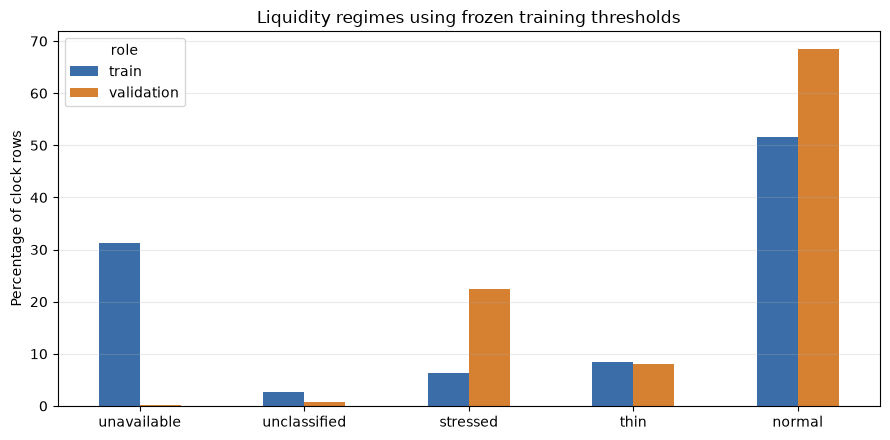

Saved: reports/figures/regime-frequency-db7e9c90d778c0a761a6243e.png


In [12]:
import matplotlib.pyplot as plt

frequency_plot = frequency_table.pivot(
    index="regime", columns="role", values="calendar_fraction"
).reindex(REGIME_NAMES)

axis = (frequency_plot * 100).plot.bar(
    figsize=(9, 4.5),
    rot=0,
    color={"train": "#3B6EA8", "validation": "#D68132"},
)
axis.set_ylabel("Percentage of clock rows")
axis.set_xlabel("")
axis.set_title("Liquidity regimes using frozen training thresholds")
axis.grid(axis="y", alpha=0.25)

figure = axis.get_figure()
figure.tight_layout()

figure_path = (
    REPO_ROOT / "reports/figures" / f"regime-frequency-{run_id}.png"
)
figure_path.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(figure_path, dpi=160)
plt.show()
plt.close(figure)

print("Saved:", relative_path(figure_path))

In [13]:
if _sha256(baseline_manifest_path) != baseline_manifest_hash:
    raise RuntimeError("The baseline manifest changed during this notebook.")
if (
    _sha256(feature_manifest_path) != input_hashes["features"]
    or _sha256(label_manifest_path) != input_hashes["labels"]
):
    raise RuntimeError("An original dataset manifest changed.")

output_dir = REPO_ROOT / "data/processed/regimes" / run_id
table_dir = REPO_ROOT / "reports/tables" / run_id
output_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

saved_dataset_paths = {}
for role, frame in regime_frames.items():
    path = output_dir / f"{role}.parquet"
    record = feature_io._save_frame(frame, path)
    run_state["files"].append({
        "kind": "regime_dataset", "role": role,
        "path": str(path), **record,
    })
    saved_dataset_paths[role] = relative_path(path)

tables = {
    "regime_frequencies": frequency_table,
    "continuous_metric_summary": continuous_table,
    "forecast_performance_by_regime": performance_table,
    "displayed_size_comparison_by_regime": comparison_table,
    "baseline_metric_reconciliation": reconciliation_table,
}
table_paths = {}
for name, table in tables.items():
    path = table_dir / f"{name}.csv"
    table.to_csv(path, index=False)
    table_paths[name] = relative_path(path)
    run_state["files"].append({
        "kind": "table",
        "path": str(path),
        "bytes": path.stat().st_size,
        "sha256": _sha256(path),
    })

run_state["files"].append({
    "kind": "figure",
    "path": str(figure_path),
    "bytes": figure_path.stat().st_size,
    "sha256": _sha256(figure_path),
})

example_path = REPO_ROOT / "configs/research_config.example.json"
local_path = REPO_ROOT / "configs/research_config.local.json"

example = json.loads(example_path.read_text(encoding="utf-8-sig"))
local = json.loads(local_path.read_text(encoding="utf-8-sig"))

if "liquidity_regimes" in local and local["liquidity_regimes"] != regime_settings:
    raise RuntimeError("A conflicting local regime specification needs review.")

example["liquidity_regimes"] = regime_settings
local.pop("liquidity_regimes", None)
local["active_regimes_manifest"] = relative_path(run_manifest_path)

feature_io.write_json(example_path, example)
feature_io.write_json(local_path, local)

environment_path = REPO_ROOT / "reports/private/validated_regimes_environment.json"
feature_io.write_json(environment_path, {
    "python": platform.python_version(),
    "packages": versions,
    "validation": test_summary,
})

method_note = f"""
### Notebook 05 — transparent liquidity regimes

Implemented trailing spread, volatility, minimum-side displayed size,
and source-snapshot activity metrics with a {W}-second lookback.

Thresholds are fitted on the saved development training window only.
High spread or volatility takes precedence over low depth or activity.
Current invalid prices are unavailable; incomplete metric sets are unclassified.
A zero current displayed size on either side is a thin condition when
the complete classification is available.

Continuous metrics and overlapping rule flags are preserved.
A stressed classification is not a data exclusion.

The unchanged Notebook 04 forecasts are evaluated by current regime.
Grouped errors reconcile with the original aggregate errors.
The pilot holdout is not loaded or evaluated.

Executed correctness checks: {test_summary}.
Real-data processing-boundary and future-append checks passed.
Notebook 05 owner review remains pending.

H001, displayed size conditional on a preceding price move, is recorded
in reports/research_hypotheses.md for later testing. No dedicated H001
experiment was executed here.

Size denomination and true quote ages remain unresolved.
The sustained-wide-spread episode investigation remains pending.
Full walk-forward uncertainty and final-test results remain pending.
"""

for relative in (
    "README.md",
    "reports/data_quality.md",
    "reports/research_results.md",
):
    update_section(REPO_ROOT / relative, "NOTEBOOK_05", method_note)

update_section(
    REPO_ROOT / "CONTRIBUTIONS.md",
    "NOTEBOOK_05",
    f"""
### Notebook 05

- Raymond Fendi requested transparent liquidity regimes and authorized
  recording the size-and-trend hypothesis for later testing.
- OpenAI Codex supplied the regime implementation, tests, and documentation.
- Executed correctness tests: {test_summary}.
- Real-data boundary, causality, alignment, and aggregate-error
  reconciliation checks passed during notebook execution.
- H001 status: recorded after the baseline pilot; dedicated testing pending.
- Notebook 05 owner review and understanding checkpoint: pending.
""",
)

private_report_path = (
    REPO_ROOT / "reports/private" / f"regimes-{run_id}.md"
)
private_report_path.parent.mkdir(parents=True, exist_ok=True)
private_report_path.write_text(
    "# Liquidity regime development diagnostics\n\n"
    "Frozen training thresholds; unchanged validation forecasts.\n\n"
    "## Frequencies\n\n```\n"
    + frequency_table.to_string(index=False)
    + "\n```\n\n## Size comparisons within regimes\n\n```\n"
    + comparison_table.to_string(index=False)
    + "\n```\n\n"
    "These diagnostics are exploratory and have no uncertainty intervals.\n"
    "They are not the dedicated H001 size-and-trend test.\n",
    encoding="utf-8",
)

run_state["validation"] = {
    "pytest": test_summary,
    "real_partition_consistency": "passed",
    "future_append_with_fixed_thresholds": "passed",
    "forecast_regime_alignment": "passed",
    "baseline_metric_reconciliation": "passed",
    "input_manifests_unchanged": "passed",
    "pilot_holdout_evaluated": False,
    "owner_review": "pending",
}
run_state["hypothesis"] = {
    "id": "H001",
    "status": "recorded; dedicated testing pending",
    "path": relative_path(hypothesis_path),
}
run_state["status"] = "complete"
feature_io.write_json(run_manifest_path, run_state)

print("Saved regime datasets, tables, thresholds, and documentation.")
print("H001 remains pending; no forecast models were changed.")

Saved regime datasets, tables, thresholds, and documentation.
H001 remains pending; no forecast models were changed.


In [14]:
def json_records(frame):
    return json.loads(frame.to_json(orient="records", date_format="iso"))


regime_frame_bytes = {
    role: int(frame.memory_usage(index=True, deep=True).sum())
    for role, frame in regime_frames.items()
}

summary = {
    "notebook": NOTEBOOK,
    "run_id": run_id,
    "python_version": platform.python_version(),
    "package_versions": versions,
    "configuration": {
        "baseline_run_id": baseline_id,
        "feature_job_id": feature_state["job_id"],
        "development_windows": windows,
        "regime_settings": regime_settings,
        "maximum_snapshot_age_seconds": feature_settings["max_staleness_seconds"],
        "volatility_return_interval_seconds": 1,
        "precedence": REGIME_NAMES,
        "thresholds": thresholds,
    },
    "inputs": input_diagnostics,
    "outputs": {
        "scope_rows": {
            role: len(frame) for role, frame in regime_frames.items()
        },
        "scope_coverage": {
            role: {
                "start_utc": frame["feature_timestamp_utc"].min().isoformat(),
                "end_utc_exclusive": (
                    frame["feature_timestamp_utc"].max()
                    + pd.Timedelta(seconds=1)
                ).isoformat(),
            }
            for role, frame in regime_frames.items()
        },
        "regime_frequencies": json_records(frequency_table),
        "metric_availability": availability_records,
        "validation_forecast_rows_by_horizon": forecast_rows_by_horizon,
        "displayed_size_comparison_by_regime": json_records(comparison_table),
        "performance_table_rows": len(performance_table),
    },
    "validation": {
        "imports_from_notebooks_directory": "passed",
        "pytest": test_summary,
        "threshold_fit_window": "training only",
        "real_partition_consistency": "passed",
        "future_append_with_fixed_thresholds": "passed",
        "forecast_regime_alignment": "passed",
        "reconciled_baseline_model_horizon_pairs": len(reconciliation_table),
        "input_manifests_unchanged": "passed",
        "forecast_models_refitted": False,
        "pilot_holdout_evaluated": False,
        "owner_review": "pending",
    },
    "hypothesis": {
        "id": "H001",
        "status": "recorded; dedicated testing pending",
        "formulated_after_notebook04_pilot": True,
        "record": relative_path(hypothesis_path),
    },
    "measurements": {
        "metric_preparation_seconds": round(metrics_runtime, 3),
        "observed_regime_frame_bytes": regime_frame_bytes,
        "regime_parquet_bytes": sum(
            item["bytes"] for item in run_state["files"]
            if item["kind"] == "regime_dataset"
        ),
        "notebook_elapsed_seconds": round(
            time.perf_counter() - notebook_started, 3
        ),
    },
    "warnings": [
        "Regimes are research definitions, not universal market classifications.",
        "Training regime labels use retrospective full-training thresholds.",
        "Validation thresholds use training data only.",
        "Regime diagnostics reuse an already inspected development sample.",
        "Missing regime metrics remain unclassified; price analysis is retained.",
        "A stressed label does not declare an observation erroneous.",
        "Quote activity and displayed sizes are not executed trade flow.",
        "Size denomination and true side-specific quote ages remain unresolved.",
        "Small-group flags do not establish independence or statistical reliability.",
        "Statistical uncertainty and full-history stability remain unassessed.",
        "The sustained-wide-spread episode investigation remains pending.",
        "H001 has not been tested by these regime diagnostics.",
        "Dataframe measurements are not total process peak memory.",
        "No achievable-profit conclusion has been established.",
    ],
    "saved_outputs": {
        "active_regimes_manifest": relative_path(run_manifest_path),
        "fitted_thresholds": relative_path(threshold_path),
        "regime_datasets": saved_dataset_paths,
        "tables": table_paths,
        "figure": relative_path(figure_path),
        "hypothesis_record": relative_path(hypothesis_path),
        "private_report": relative_path(private_report_path),
        "validated_environment": relative_path(environment_path),
        "execution_summary": "reports/private/notebook05_execution.json",
    },
}

feature_io.write_json(
    REPO_ROOT / "reports/private/notebook05_execution.json", summary
)

print("NOTEBOOK_05_SUMMARY")
print(json.dumps(summary, indent=2, allow_nan=False))

NOTEBOOK_05_SUMMARY
{
  "notebook": "05_liquidity_regimes.ipynb",
  "run_id": "db7e9c90d778c0a761a6243e",
  "python_version": "3.14.8",
  "package_versions": {
    "numpy": "2.5.4",
    "pandas": "3.0.6",
    "pyarrow": "26.0.0",
    "duckdb": "2.0.0",
    "pytest": "9.1.1",
    "matplotlib": "3.11.2"
  },
  "configuration": {
    "baseline_run_id": "954fa0296d02480ea2d473c0",
    "feature_job_id": "fb7eb0c3f6e51a16fe2e8ee5",
    "development_windows": {
      "train": {
        "end_utc": "2016-01-20T00:00:00+00:00",
        "selected_active_dates": [
          "2016-01-17",
          "2016-01-18",
          "2016-01-19"
        ],
        "start_utc": "2016-01-17T00:00:00+00:00"
      },
      "validation": {
        "end_utc": "2016-01-22T00:00:00+00:00",
        "selected_active_dates": [
          "2016-01-20",
          "2016-01-21"
        ],
        "start_utc": "2016-01-20T00:00:00+00:00"
      }
    },
    "regime_settings": {
      "lookback_seconds": 60,
      "high_quantil